In [4]:
%pip install -r ../requirements.txt
%pip install scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer

df = pd.read_csv("../data/bangladesh_data.csv")
df.head()

  Using cached numpy-1.26.4.tar.gz (15.8 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Installing backend dependencies: started
  Installing backend dependencies: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [21 lines of output]
      + c:\Users\Admin\AppData\Local\Programs\Python\Python313\python.exe C:\Users\Admin\AppData\Local\Temp\pip-install-lo3xk56n\numpy_72b81b95593c4421a4a5aa68533082e5\vendored-meson\meson\meson.py setup C:\Users\Admin\AppData\Local\Temp\pip-install-lo3xk56n\numpy_72b81b95593c4421a4a5aa68533082e5 C:\Users\Admin\AppData\Local\Temp\pip-install-lo3xk56n\numpy_72b81b95593c4421a4a5aa68533082e5\.mesonpy-zj3s10en -Dbuildtype=release -Db_ndebug=if-release -Db_vscrt=md --native-file=C:\Users\Admin\AppData\Local\Temp\pip-install-lo3xk56n\numpy_72b81b95593c4421a4a5aa68533082e5\.mesonpy-zj3s10en\meson-python-native-file.ini
      The Meson build system
      Version: 1.2.99
      Source dir: C:\Users\Admin\AppData\Local\Temp\pip-install-lo3xk56n\numpy_72b81b95593c4421a4a5aa68533082e5
      Build dir: C:\Users\Admin\AppData\Local\Temp\pip-install-lo3

Note: you may need to restart the kernel to use updated packages.


,I Agree to participate in the research project under the conditions described above,The name of your institution\r\n,The name of your program of study\r\n,Your current class level is,Your gender,Your current age,Living with family?,Are you happy with your academic Condition?,Your CGPA,Are you addicted to any drugs?,...,"1. _____ Extraverted, enthusiastic.","2. _____ Critical, quarrelsome.","3. _____ Dependable, self-disciplined.","4. _____ Anxious, easily upset.","5. _____ Open to new experiences, complex.","6. _____ Reserved, quiet.","7. _____ Sympathetic, warm.","8. _____ Disorganized, careless.","9. _____ Calm, emotionally stable","10. _____ Conventional, uncreative."
0,"Yes, I agree to participate,",EDU,CSE,Freshman (Undergrad),Female,> 25,Yes,Yes,3.01-3.50,No,...,1,5,4,7,7,7,7,5,1,1
1,"Yes, I agree to participate,",EDU,CSE,Senior (Undergrad),Male,21-25,Yes,Yes,3.01-3.50,No,...,6,5,2,7,5,4,7,5,1,5
2,"Yes, I agree to participate,",East Delta University,Computer Science and Engineering,Senior (Undergrad),Male,> 25,Yes,Yes,> 3.50,No,...,2,5,7,2,5,6,5,5,3,2
3,"Yes, I agree to participate,",East Delta University,CSE,Senior (Undergrad),Female,21-25,Yes,Yes,> 3.50,No,...,1,1,3,4,6,4,6,5,6,1
4,"Yes, I agree to participate,",East Delta University,BSC in CSE,Senior (Undergrad),Male,21-25,Yes,Yes,> 3.50,No,...,2,5,6,6,5,5,5,5,3,3


In [5]:
df.shape

(571, 35)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 571 entries, 0 to 570
Data columns (total 35 columns):
 #   Column                                                                                                                                           Non-Null Count  Dtype
---  ------                                                                                                                                           --------------  -----
 0   I Agree to participate in the research project under the conditions described above                                                              571 non-null    str  
 1   The name of your institution
                                                                                                                   571 non-null    str  
 2   The name of your program of study
                                                                                                              571 non-null    str  
 3   Your current class level is                

In [7]:
df.isna().sum()

I Agree to participate in the research project under the conditions described above                                                                  0
The name of your institution\r\n                                                                                                                     0
The name of your program of study\r\n                                                                                                                0
Your current class level is                                                                                                                          0
Your gender                                                                                                                                          0
Your current age                                                                                                                                     0
Living with family?                                                                           

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,1. I found it hard to wind down\r\n??? ??????? ?? ???????????? ????? ?? ????????? ???????? ???? ??? ???? ???? ???? ???,2. I tended to over-react to situations \r\n???? ????? ??????? ??????????? ???????? ???????????? ???? ??????? ???,3 .I felt that I was using a lot of nervous energy \r\n???? ??? ??? ?? ??? ??? ???? ??????? ???? ?????,4. I found myself getting agitated \r\n??? ????? ????? ?? ??? ??? ?????? ???? ???????,5. I found it difficult to relax \r\n???? ??? ??? ???? ???? ???? ??,6. I was intolerant of anything that kept me from getting on with what I was doing \r\n???? ???? ???? ??? ??? ?? ??? ?????? ???? ???? ????? ????,7. I felt that I was rather touchy \r\n??? ????? ????? ??? ??????? ??? ?????? ???,"1. _____ Extraverted, enthusiastic.","2. _____ Critical, quarrelsome.","3. _____ Dependable, self-disciplined.","4. _____ Anxious, easily upset.","5. _____ Open to new experiences, complex.","6. _____ Reserved, quiet.","7. _____ Sympathetic, warm.","8. _____ Disorganized, careless.","9. _____ Calm, emotionally stable","10. _____ Conventional, uncreative."
count,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000,571.000000
mean,1.332750,1.457093,1.621716,1.760070,1.555166,1.851138,1.632224,3.674256,3.201401,4.523643,4.322242,4.802102,4.488616,5.105079,4.003503,4.129597,3.425569
std,0.988333,1.051064,1.064821,1.059733,1.065415,1.029688,1.136914,2.059387,1.950186,1.792005,2.197569,1.865964,2.016022,1.698139,1.820928,2.024590,1.995428
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,3.000000,2.000000,4.000000,3.000000,4.000000,2.000000,3.000000,2.000000
50%,1.000000,1.000000,2.000000,2.000000,1.000000,2.000000,2.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000,3.000000
75%,2.000000,2.000000,3.000000,3.000000,2.500000,3.000000,3.000000,5.000000,5.000000,6.000000,6.000000,6.000000,6.000000,6.000000,5.000000,6.000000,5.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000


In [10]:
df.columns = ['agree', 'institution_name', 'program_name', 'class_level', 'gender', 'age', 'family', 'academic_condition', 'cgpa', 'drugs', 'relationship_status', 'breakup', 'conflict', 'finance', 'violence', 'bullied', 'sa', 'social_media', 'DASS_1', 'DASS_2', 'DASS_3', 'DASS_4', 'DASS_5', 'DASS_6', 'DASS_7', 'TIPI_1', 'TIPI_2', 'TIPI_3', 'TIPI_4', 'TIPI_5', 'TIPI_6', 'TIPI_7', 'TIPI_8', 'TIPI_9', 'TIPI_10']
df.head()

,agree,institution_name,program_name,class_level,gender,age,family,academic_condition,cgpa,drugs,...,TIPI_1,TIPI_2,TIPI_3,TIPI_4,TIPI_5,TIPI_6,TIPI_7,TIPI_8,TIPI_9,TIPI_10
0,"Yes, I agree to participate,",EDU,CSE,Freshman (Undergrad),Female,> 25,Yes,Yes,3.01-3.50,No,...,1,5,4,7,7,7,7,5,1,1
1,"Yes, I agree to participate,",EDU,CSE,Senior (Undergrad),Male,21-25,Yes,Yes,3.01-3.50,No,...,6,5,2,7,5,4,7,5,1,5
2,"Yes, I agree to participate,",East Delta University,Computer Science and Engineering,Senior (Undergrad),Male,> 25,Yes,Yes,> 3.50,No,...,2,5,7,2,5,6,5,5,3,2
3,"Yes, I agree to participate,",East Delta University,CSE,Senior (Undergrad),Female,21-25,Yes,Yes,> 3.50,No,...,1,1,3,4,6,4,6,5,6,1
4,"Yes, I agree to participate,",East Delta University,BSC in CSE,Senior (Undergrad),Male,21-25,Yes,Yes,> 3.50,No,...,2,5,6,6,5,5,5,5,3,3


In [11]:
df['agree'].value_counts(dropna=False)

agree
Yes, I agree to participate,    571
Name: count, dtype: int64

In [12]:
print(df['institution_name'].value_counts(dropna=False).to_string())

institution_name
East Delta University                                                       60
East Delta University                                                       36
University of Dhaka                                                         27
CUET                                                                        20
University of Dhaka                                                         19
University of Chittagong                                                    14
BUET                                                                        13
Ahsanullah University of Science and Technology                             12
Dhaka University                                                            11
EDU                                                                          8
University of Chittagong                                                     8
American International University - Bangladesh                               7
Chittagong University of Engineerin

In [13]:
print(df['program_name'].value_counts(dropna=False).to_string())

program_name
CSE                                                       71
EEE                                                       34
Computer science and engineering                          24
BBA                                                       17
Electrical & Electronic Engineering                       17
Cse                                                       15
Physics                                                   13
Computer Science and Engineering                           8
CSE                                                        8
Law                                                        7
MBBS                                                       7
BSc in CSE                                                 7
Computer Science and Engineering                           6
Mechanical Engineering                                     6
MBA                                                        5
LLB                                                        5
Management 

In [14]:
df['class_level'].value_counts(dropna=False)

class_level
Senior (Undergrad)       236
Graduate student         114
Junior (Undergrad)       104
Freshman (Undergrad)      64
Sophomore (Undergrad)     53
Name: count, dtype: int64

In [15]:
df['gender'].value_counts(dropna=False)

gender
Male                 319
Female               246
Prefer not to say      6
Name: count, dtype: int64

In [16]:
df['age'].value_counts(dropna=False)

age
21-25    460
> 25      75
< 20      36
Name: count, dtype: int64

In [17]:
df['family'].value_counts(dropna=False)

family
Yes    417
No     154
Name: count, dtype: int64

In [18]:
df['academic_condition'].value_counts(dropna=False)

academic_condition
No     324
Yes    247
Name: count, dtype: int64

In [19]:
df['cgpa'].value_counts(dropna=False)

cgpa
3.01-3.50    287
> 3.50       158
< 3.00       126
Name: count, dtype: int64

In [20]:
df['drugs'].value_counts(dropna=False)

drugs
No     519
Yes     52
Name: count, dtype: int64

In [21]:
df['relationship_status'].value_counts(dropna=False)

relationship_status
No     396
Yes    175
Name: count, dtype: int64

In [22]:
df['breakup'].value_counts(dropna=False)

breakup
No     448
Yes    123
Name: count, dtype: int64

In [23]:
df['conflict'].value_counts(dropna=False)

conflict
Sometimes           364
Never occurs        169
Most of the time     38
Name: count, dtype: int64

In [24]:
df['finance'].value_counts(dropna=False)

finance
No     291
Yes    280
Name: count, dtype: int64

In [25]:
df['violence'].value_counts(dropna=False)

violence
Never               247
Rarely              213
Often                66
Most of the time     45
Name: count, dtype: int64

In [26]:
df['bullied'].value_counts(dropna=False)

bullied
Yes    345
No     226
Name: count, dtype: int64

In [27]:
df['sa'].value_counts(dropna=False)

sa
No       360
Yes      162
Maybe     49
Name: count, dtype: int64

In [28]:
df['social_media'].value_counts(dropna=False)

social_media
> 3 Hours    313
1-3 Hours    212
< 1 Hours     46
Name: count, dtype: int64

In [29]:
df['DASS_1'].value_counts(dropna=False)

DASS_1
1    209
2    147
0    129
3     86
Name: count, dtype: int64

In [30]:
df['TIPI_1'].value_counts(dropna=False)

TIPI_1
1    108
2     87
5     87
4     81
6     78
3     61
7     58
0     11
Name: count, dtype: int64

In [31]:
df['TIPI_2'].value_counts(dropna=False)

TIPI_2
1    122
5    109
2     92
4     77
3     63
6     59
0     31
7     18
Name: count, dtype: int64

In [32]:
df['TIPI_3'].value_counts(dropna=False)

TIPI_3
5    121
6    120
4     91
7     78
3     78
2     38
1     38
0      7
Name: count, dtype: int64

In [33]:
df['TIPI_4'].value_counts(dropna=False)

TIPI_4
7    117
5    103
6     95
1     78
4     63
2     48
3     46
0     21
Name: count, dtype: int64

In [34]:
df_cleana = df.copy().drop_duplicates()

In [35]:
program_map = {
    "cse": "Computer Science & Engineering",
    "computer science and engineering": "Computer Science & Engineering",
    "computer science engineering": "Computer Science & Engineering",
    "computer science & engineering": "Computer Science & Engineering",
    "computer science & engineering (cse)": "Computer Science & Engineering",
    "computer science": "Computer Science",
    "cs": "Computer Science",
    "c.s.e.": "Computer Science & Engineering",
    "bsc in cse": "Computer Science & Engineering",
    "bsc in computer science and engineering": "Computer Science & Engineering",
    "bsc engineering in computer science and engineering": "Computer Science & Engineering",
    "bsc engineering in cse": "Computer Science & Engineering",
    "b.sc in cse": "Computer Science & Engineering",
    "b.sc. in cse": "Computer Science & Engineering",
    "b.sc in computer science & engineering": "Computer Science & Engineering",
    "bsc in computer science & engineering": "Computer Science & Engineering",
    "cse undergrad": "Computer Science & Engineering",
    "eee": "Electrical & Electronic Engineering",
    "electrical & electronic engineering": "Electrical & Electronic Engineering",
    "electrical and electronic engineering": "Electrical & Electronic Engineering",
    "electrical and electronics engineering": "Electrical & Electronic Engineering",
    "electrical and electronic engineering": "Electrical & Electronic Engineering",
    "electrical &electronics engineering": "Electrical & Electronic Engineering",
    "electrical engineering": "Electrical & Electronic Engineering",
    "bsc in eee": "Electrical & Electronic Engineering",
    "bsc in electrical engineering": "Electrical & Electronic Engineering",
    "b.sc in eee": "Electrical & Electronic Engineering",
    "b.sc. in eee": "Electrical & Electronic Engineering",
    "bsc engineering in eee": "Electrical & Electronic Engineering",
    "bba": "Business Administration",
    "bba in hrm": "Business Administration",
    "bba (professional)": "Business Administration",
    "bba (hon's) department of marketing": "Business Administration",
    "bba honour's at managment": "Business Administration",
    "bachelors of business administration": "Business Administration",
    "bachelor of business administration": "Business Administration",
    "bbs": "Business Administration",
    "physics": "Physics",
    "physics department": "Physics",
    "bsc in physics": "Physics",
    "b.sc. in physics": "Physics",
    "b.sc honours at department of physics": "Physics",
    "b.s honors in physics": "Physics",
    "bs honours in physics": "Physics",
    "bs honours in physics": "Physics",
    "bsc. hons. in physics": "Physics",
    "bsc- physics": "Physics",
    "msc in physics": "Physics",
    "law": "Law",
    "llb": "Law",
    "l.l.b": "Law",
    "ll.b.": "Law",
    "ll.b": "Law",
    "llb (hons.)": "Law",
    "llb honours": "Law",
    "llb(honors)": "Law",
    "bachelor of law": "Law",
    "law department": "Law",
    "llm": "LLM",
    "llm(hr)": "LLM",
    "english": "English",
    "english literature and culture m.a.": "English",
    "english language and literature": "English",
    "english language and literature": "English",
    "english literature": "English",
    "department of english": "English",
    "ba in english": "English",
    "ba(english)": "English",
    "b.a. in english": "English",
    "b.a in english": "English",
    "ma in english": "English",
    "m.a in english": "English",
    "masters in english language teaching": "English",
    "english language and literature": "English",
    "english language and literature": "English",
    "civil": "Civil Engineering",
    "civil engineering": "Civil Engineering",
    "department of civil engineering": "Civil Engineering",
    "bsc in civil engineering": "Civil Engineering",
    "b.sc. in civil engineering": "Civil Engineering",
    "mechanical engineering": "Mechanical Engineering",
    "me": "Mechanical Engineering",
    "b.sc in mechanical engineering": "Mechanical Engineering",
    "textile engineering": "Textile Engineering",
    "b.sc in textile engineering": "Textile Engineering",
    "bsc in textile engineering": "Textile Engineering",
    "apparel engineering": "Apparel Engineering",
    "fabric manufacturing": "Fabric Manufacturing",
    "bsc in yarn engineering": "Yarn Engineering",
    "chemical engineering": "Chemical Engineering",
    "chemistty": "Chemistry",
    "chemistry department": "Chemistry",
    "botany": "Botany",
    "zoology": "Zoology",
    "msc in zoology": "Zoology",
    "bsc in zoology": "Zoology",
    "microbiology": "Microbiology",
    "microbiology and biotechnology": "Microbiology & Biotechnology",
    "genetic engineering & biotechnology": "Genetic Engineering & Biotechnology",
    "fisheries": "Fisheries",
    "b.sc. fisheries( hons.)": "Fisheries",
    "bachelor of science in nursing": "Nursing",
    "bsc. in nursing": "Nursing",
    "diploma in nursing science and midwifery": "Nursing",
    "diploma in nursing": "Nursing",
    "medicine": "Medicine",
    "pharmacy": "Pharmacy",
    "optometry": "Optometry",
    "history": "History",
    "history": "History",
    "islamic history": "Islamic History",
    "islamic studies economic and banking": "Islamic Studies",
    "religious studies": "Religious Studies",
    "sociology": "Sociology",
    "philosophy": "Philosophy",
    "peace and conflict": "Peace and Conflict Studies",
    "folklore studies": "Folklore Studies",
    "bss hons folklore studies": "Folklore Studies",
    "geography and environment": "Geography & Environment",
    "geography& environment": "Geography & Environment",
    "ms (geography & environment)": "Geography & Environment",
    "economics": "Economics",
    "economic department": "Economics",
    "bss honors": "Social Science",
    "bachelor of social science": "Social Science",
    "ete": "Electronics & Telecommunication Engineering",
    "electronics technology": "Electronics Technology",
    "petroleum and mining engineering": "Petroleum & Mining Engineering",
    "mechatronics & industrial engineering": "Mechatronics & Industrial Engineering",
    "department of mechatronics and industrial engineering": "Mechatronics & Industrial Engineering",
    "mie": "Mechatronics & Industrial Engineering",
    "wre": "Water Resources Engineering",
    "urp": "Urban & Regional Planning",
    "computer and communication engineering": "Computer & Communication Engineering",
    "architectural visualisation": "Architecture",
    "architecture": "Architecture",
    "drawing and painting": "Drawing & Painting",
    "visual art": "Visual Art",
    "fashion design and technology": "Fashion Design & Technology",
    "food science and technology": "Food Science & Technology",
    "mathematics": "Mathematics",
    "math department": "Mathematics",
    "statistics": "Statistics",
    "ir": "International Relations",
    "masters in public health": "Public Health",
    "master of data science and innovation": "Data Science & Innovation",
    "mphil": "MPhil",
    "graduated": "Alumni",
    "under graduation": "Undergrad",
    "mbbs": "MBBS",
    "hsc": "HSc",
    "bsc": "BSc",
    "b.sc": "BSc",
    "bsc. in computer science  & engineering": "Computer Science & Engineering",
    "bsc in cse (graduate)": "Computer Science & Engineering",
    "b a honours": "BA",
    "b.a (hon's), m.a in history": "History",
    "ba honours": "BA",
    "b.a honours": "BA",
    "bss honors 2nd year(economics)": "Economics",
    "bachelor of science  in nursing": "Nursing",
    "b.sc  in  eee": "Electrical & Electronic Engineering",
    "bsc. in cse": "Computer Science & Engineering",
    "b.sc honours": "BSc",
    "bsc engineering": "Engineering",
    "b.sc": "BSc",
    "hons.": "Honours",
    "b.a honors": "BA",
    "completed bsc": "BSc",
    "b.sc(honour's)": "BSc",
    "bsc in honours": "BSc",
    "bs honours": "BSc",
    "bsc. in physics": "Physics",
    "bss honours": "BSS",
    "depterment of physics": "Physics",
    "b.a.(hon's)": "BA",
    "intermediate at science": "Science",
    "science": "Science",
    "honours 1st year ,session (21-22)": "Honours",
    "science background hsc": "Science",
    "bsc hons": "BSc",
    "hsc science": "Science",
    "doctor of philosophy (ph.d.)": "Philosophy",
    "honors": "Honours",
    "b.a in ell": "ELL",
    "accounts": "Accounting",
}

df_cleana["program_name"] = (
    df_cleana["program_name"].str.strip().str.lower().map(program_map).fillna(df_cleana["program_name"].str.strip())
)

institution_map = {
    "east delta university": "East Delta University",
    "east delta": "East Delta University",
    "edu": "East Delta University",
    "east delta university, chittagong": "East Delta University",
    "east delta university,chittagong": "East Delta University",
    "east delta university": "East Delta University",
    "east  delta  university": "East Delta University",
    "east delta university": "East Delta University",
    "university of dhaka": "University of Dhaka",
    "dhaka university": "University of Dhaka",
    "du": "University of Dhaka",
    "university  of  dhaka": "University of Dhaka",
    "the university of dhaka": "University of Dhaka",
    "dhaka university": "University of Dhaka",
    "dhaka university": "University of Dhaka",
    "dhaka university": "University of Dhaka",
    "university of chittagong": "University of Chittagong",
    "chittagong university": "University of Chittagong",
    "chattogram university": "University of Chittagong",
    "university of chittagong.": "University of Chittagong",
    "university of chittagong": "University of Chittagong",
    "university of chittagong": "University of Chittagong",
    ",chittagong university": "University of Chittagong",
    "chittagong university": "University of Chittagong",
    "buet": "Bangladesh University of Engineering and Technology",
    "bangladesh university of engineering and technology": "Bangladesh University of Engineering and Technology",
    "bangladesh university of engineering and technology": "Bangladesh University of Engineering and Technology",
    "cuet": "Chittagong University of Engineering and Technology",
    "cuetu": "Chittagong University of Engineering and Technology",
    "c.u.e.t.": "Chittagong University of Engineering and Technology",
    "chittagong university of engineering and technology": "Chittagong University of Engineering and Technology",
    "chittagong university of engineering & technology": "Chittagong University of Engineering and Technology",
    "chittagong university of engineering and technology (cuet)": "Chittagong University of Engineering and Technology",
    "chittagong university of engineering & technology": "Chittagong University of Engineering and Technology",
    "ahsanullah university of science and technology": "Ahsanullah University of Science and Technology",
    "ahsanullah university of science & technology": "Ahsanullah University of Science and Technology",
    "aiub": "American International University-Bangladesh",
    "american international university - bangladesh": "American International University-Bangladesh",
    "brac university": "BRAC University",
    "brac": "BRAC University",
    "bracu": "BRAC University",
    "north south university": "North South University",
    "rajshahi university of engineering & technology": "Rajshahi University of Engineering & Technology",
    "national university": "National University",
    "east west university": "East West University",
    "iiuc": "International Islamic University Chittagong",
    "iuc": "International Islamic University Chittagong",
    "international islamic university chittagong": "International Islamic University Chittagong",
    "international islamic university, chittagong": "International Islamic University Chittagong",
    "international islamic university,chittagong": "International Islamic University Chittagong",
    "port city international university": "Port City International University",
    "port city international university": "Port City International University",
    "portcity international university": "Port City International University",
    "portcity international  university": "Port City International University",
    "port city international  university": "Port City International University",
    "port city internation university": "Port City International University",
    "port city university": "Port City International University",
    "pciu": "Port City International University",
    "pcu": "Port City International University",
    "premier university": "Premier University",
    "premier university chittagong": "Premier University",
    "chittagong independent university": "Chittagong Independent University",
    "islamic university": "Islamic University, Kushtia",
    "islamic university kushtia": "Islamic University, Kushtia",
    "islamic university, kushtia": "Islamic University, Kushtia",
    "islamic university,bangladesh": "Islamic University, Kushtia",
    "islamic university bangladesh": "Islamic University, Kushtia",
    "uttara university": "Uttara University",
    "cvasu": "Chattogram Veterinary and Animal Sciences University",
    "chattogram veterinary and animal sciences university": "Chattogram Veterinary and Animal Sciences University",
    "chattogram veterinary &animal sciences university": "Chattogram Veterinary and Animal Sciences University",
    "chittagong college": "Chittagong College",
    "chattogram college": "Chittagong College",
    "chittagong college, chattogarm": "Chittagong College",
    "chittagong college,(national university)": "Chittagong College",
    "dhaka college": "Dhaka College",
    "govt.hazi mohammad mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "govt. hazi mohammad mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "govt. hazi mohammed mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "govt hazi muhammad mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "govt hazi mohammed mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "govt. haji mohammad mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "govt hazi mohammad mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "govt.hazi mohammad mohsin college chattagram": "Govt. Hazi Mohammad Mohsin College",
    "govt. hazi mohammad mohsin college, chattogram": "Govt. Hazi Mohammad Mohsin College",
    "govt. hazi mohammad mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "govt. city college, chittagong": "Govt. City College, Chittagong",
    "govt.city college,chittagong": "Govt. City College, Chittagong",
    "govt. city clg,  chittagong": "Govt. City College, Chittagong",
    "govt. city college, chittagong": "Govt. City College, Chittagong",
    "chittagong govt women's college": "Chittagong Govt. Women's College",
    "chittagong govt. women's college": "Chittagong Govt. Women's College",
    "chittagong govt girls college": "Chittagong Govt. Women's College",
    "chittagong govt. girls college": "Chittagong Govt. Women's College",
    "chittagong government women college": "Chittagong Govt. Women's College",
    "chittagong government girls college": "Chittagong Govt. Women's College",
    "ctg. govt. women's college": "Chittagong Govt. Women's College",
    "cgwc": "Chittagong Govt. Women's College",
    "rajuk uttara model college": "Rajuk Uttara Model College",
    "mymensingh medical college": "Mymensingh Medical College",
    "khulna medical college": "Khulna Medical College",
    "rangamati medical college": "Rangamati Medical College",
    "rangpur medical college": "Rangpur Medical College",
    "mainamoti medical.college": "Mainamoti Medical College",
    "east west medical college": "East West Medical College",
    "ustc medical college": "USTC Medical College",
    "bgc trust medical college hospital.": "BGC Trust Medical College Hospital",
    "abdul malek ukil medical college,noakhali": "Abdul Malek Ukil Medical College",
    "abdul malek ukil medical college": "Abdul Malek Ukil Medical College",
    "abdul malek ukil medical College": "Abdul Malek Ukil Medical College",
    "amumc": "Abdul Malek Ukil Medical College",
    "shamsun nahar khan nursing college,  chattogram": "Shamsun Nahar Khan Nursing College",
    "progoti nursing college": "Progoti Nursing College",
    "south asian nursing college.": "South Asian Nursing College",
    "institute of community ophthalmology": "Institute of Community Ophthalmology",
    "southeast university": "Southeast University",
    "european university": "European University",
    "khulna university": "Khulna University",
    "jagannath university": "Jagannath University",
    "united international university": "United International University",
    "stamford university bangladesh": "Stamford University Bangladesh",
    "daffodil university": "Daffodil International University",
    "daffodil international university": "Daffodil International University",
    "eastern university": "Eastern University",
    "southern university bangladesh": "Southern University Bangladesh",
    "city university": "City University",
    "leading university": "Leading University",
    "university of asia pacific": "University of Asia Pacific",
    "university of south asia": "University of South Asia",
    "university of technology sydney": "University of Technology Sydney",
    "australian catholic university (acu)": "Australian Catholic University",
    "university of barishal": "University of Barishal",
    "noakhali science and technology university": "Noakhali Science and Technology University",
    "comilla university": "Comilla University",
    "jadarvpur university": "Jadavpur University",
    "jadavpur university": "Jadavpur University",
    "yangzhou university": "Yangzhou University",
    "nanjing university of aeronautics and astronautics": "Nanjing University of Aeronautics and Astronautics",
    "eberhard karls universit�t t�bingen": "University of Tübingen",
    "university of tuebingen": "University of Tübingen",
    "sust": "Shahjalal University of Science & Technology",
    "shahajalal university of science & technology": "Shahjalal University of Science & Technology",
    "bsmrstu": "Bangabandhu Sheikh Mujibur Rahman Science and Technology University",
    "bup": "Bangladesh University of Professionals",
    "iubat-international university of business agriculture and technology": "IUBAT",
    "iub": "Independent University, Bangladesh",
    "uits": "University of Information Technology and Sciences",
    "kuet": "Khulna University of Engineering & Technology",
    "khulna university of engineering & technology": "Khulna University of Engineering & Technology",
    "duet": "Dhaka University of Engineering and Technology",
    "butex": "Bangladesh University of Textiles",
    "national institute of textile engineering & research (niter)": "National Institute of Textile Engineering & Research",
    "chittagong bgmea institute of fashion & technology": "Chittagong BGMEA Institute of Fashion & Technology",
    "textile engineering college,begumganj": "Textile Engineering College, Begumganj",
    "textile engineering college, chattogram": "Textile Engineering College, Chattogram",
    "shahid abdur rab serniabat textile engineering college, barishal": "Shahid Abdur Rab Serniabat Textile Engineering College",
    "institute of science & technology (ist)": "Institute of Science & Technology",
    "institute of forestry and environmental sciences, chittagong university": "Institute of Forestry and Environmental Sciences, University of Chittagong",
    "institute of photography": "Institute of Photography",
    "sec": "SEC",
    "hfwu": "HFWU",
    "government commerce college": "Government Commerce College",
    "govt.commerce  college": "Government Commerce College",
    "govt. college  of commerce, ctg": "Government Commerce College",
    "chattogram bandar college": "Chattogram Bandar College",
    "chattogram government college": "Chattogram College",
    "hazera-taju degree college": "Hazera-Taju Degree College",
    "eden mohila college": "Eden Mohila College",
    "lalmatia mohila college,dhaka.": "Lalmatia Mohila College",
    "lalmatia mohila college": "Lalmatia Mohila College",
    "gurudayal government college": "Gurudayal Government College",
    "carmichael college rangpur": "Carmichael College Rangpur",
    "siddheswari college": "Siddheswari College",
    "netrokona govt clg": "Netrokona Government College",
    "govt. bl. university college, khulna": "Govt. B.L. University College, Khulna",
    "govt bangabandhu college khulna": "Govt. Bangabandhu College, Khulna",
    "govt. syed hatem ali college, barisal": "Govt. Syed Hatem Ali College, Barisal",
    "islamia degree college": "Islamia Degree College",
    "islamia university college": "Islamia University College",
    "abu dharr ghifari college": "Abu Dharr Ghifari College",
    "savar model college": "Savar Model College",
    "bepza public school and college": "BEPZA Public School and College",
    "mohila college chottogram": "Mohila College, Chittagong",
    "kapasgola city corporation mohila college": "Kapasgola City Corporation Mohila College",
    "bandarban gov.college": "Bandarban Government College",
    "govt. hazi mohammad mohsin college": "Govt. Hazi Mohammad Mohsin College",
    "i don't want to share": "Prefer not to say",
    "not studying currently": "Not currently studying",
    "not available at the moment": "Not available",
    "khalida akther asha": "Khalida Akther Asha",
    "professionalä school of business": "Professional School of Business",
    "হাজী সোনামিয়া ডিগ্রী কলেজ": "Haji Sonamia Degree College",
}

df_cleana["institution_name"] = (
    df_cleana["institution_name"].str.strip().str.lower().map(institution_map).fillna(df_cleana["institution_name"].str.strip())
)


In [36]:
print(df_cleana['institution_name'].value_counts(dropna=False).to_string())

institution_name
East Delta University                                                         127
University of Dhaka                                                            70
Chittagong University of Engineering and Technology                            48
University of Chittagong                                                       36
Bangladesh University of Engineering and Technology                            23
Port City International University                                             17
Ahsanullah University of Science and Technology                                14
BRAC University                                                                13
International Islamic University Chittagong                                    11
American International University-Bangladesh                                   10
National University                                                             8
Govt. Hazi Mohammad Mohsin College                                              8

In [37]:
print("Rows after removing duplicates:", len(df_cleana))

Rows after removing duplicates: 571


In [38]:
print(df_cleana["program_name"].value_counts(dropna=False).to_string())

program_name
Computer Science & Engineering                 166
Electrical & Electronic Engineering             70
Physics                                         34
Business Administration                         31
Law                                             24
English                                         21
BSc                                             17
MBBS                                            13
Civil Engineering                               12
Mechanical Engineering                          12
Science                                         10
Honours                                          9
HSc                                              8
MBA                                              5
BA                                               5
Fisheries                                        5
History                                          5
Management                                       5
Architecture                                     5
Food Science & Tec

In [39]:
print(df_cleana["institution_name"].value_counts(dropna=False).to_string())

institution_name
East Delta University                                                         127
University of Dhaka                                                            70
Chittagong University of Engineering and Technology                            48
University of Chittagong                                                       36
Bangladesh University of Engineering and Technology                            23
Port City International University                                             17
Ahsanullah University of Science and Technology                                14
BRAC University                                                                13
International Islamic University Chittagong                                    11
American International University-Bangladesh                                   10
National University                                                             8
Govt. Hazi Mohammad Mohsin College                                              8

In [40]:
df_cleana.insert(0, 'New_ID', range(0, 0 + len(df)))
df_cleana

,New_ID,agree,institution_name,program_name,class_level,gender,age,family,academic_condition,cgpa,...,TIPI_1,TIPI_2,TIPI_3,TIPI_4,TIPI_5,TIPI_6,TIPI_7,TIPI_8,TIPI_9,TIPI_10
0,0,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Freshman (Undergrad),Female,> 25,Yes,Yes,3.01-3.50,...,1,5,4,7,7,7,7,5,1,1
1,1,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Senior (Undergrad),Male,21-25,Yes,Yes,3.01-3.50,...,6,5,2,7,5,4,7,5,1,5
2,2,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Senior (Undergrad),Male,> 25,Yes,Yes,> 3.50,...,2,5,7,2,5,6,5,5,3,2
3,3,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Senior (Undergrad),Female,21-25,Yes,Yes,> 3.50,...,1,1,3,4,6,4,6,5,6,1
4,4,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Senior (Undergrad),Male,21-25,Yes,Yes,> 3.50,...,2,5,6,6,5,5,5,5,3,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
566,566,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Junior (Undergrad),Female,21-25,Yes,Yes,3.01-3.50,...,7,2,7,5,5,5,5,2,7,2
567,567,"Yes, I agree to participate,",USTC,Pharmacy,Junior (Undergrad),Male,21-25,Yes,Yes,3.01-3.50,...,4,4,4,4,4,4,4,4,4,4
568,568,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Sophomore (Undergrad),Male,21-25,Yes,Yes,3.01-3.50,...,5,6,5,5,7,6,6,5,5,1
569,569,"Yes, I agree to participate,",East Delta University,Engineering,Senior (Undergrad),Male,21-25,Yes,No,< 3.00,...,4,4,5,2,4,4,4,4,4,4


In [41]:
df_cleana["DASS_total"] = df_cleana["DASS_1"] + df_cleana["DASS_2"] + df_cleana["DASS_3"] + df_cleana["DASS_4"] + df_cleana["DASS_5"] + df_cleana["DASS_6"] + df_cleana["DASS_7"]
df_cleana

,New_ID,agree,institution_name,program_name,class_level,gender,age,family,academic_condition,cgpa,...,TIPI_2,TIPI_3,TIPI_4,TIPI_5,TIPI_6,TIPI_7,TIPI_8,TIPI_9,TIPI_10,DASS_total
0,0,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Freshman (Undergrad),Female,> 25,Yes,Yes,3.01-3.50,...,5,4,7,7,7,7,5,1,1,12
1,1,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Senior (Undergrad),Male,21-25,Yes,Yes,3.01-3.50,...,5,2,7,5,4,7,5,1,5,15
2,2,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Senior (Undergrad),Male,> 25,Yes,Yes,> 3.50,...,5,7,2,5,6,5,5,3,2,0
3,3,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Senior (Undergrad),Female,21-25,Yes,Yes,> 3.50,...,1,3,4,6,4,6,5,6,1,7
4,4,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Senior (Undergrad),Male,21-25,Yes,Yes,> 3.50,...,5,6,6,5,5,5,5,3,3,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
566,566,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Junior (Undergrad),Female,21-25,Yes,Yes,3.01-3.50,...,2,7,5,5,5,5,2,7,2,5
567,567,"Yes, I agree to participate,",USTC,Pharmacy,Junior (Undergrad),Male,21-25,Yes,Yes,3.01-3.50,...,4,4,4,4,4,4,4,4,4,6
568,568,"Yes, I agree to participate,",East Delta University,Computer Science & Engineering,Sophomore (Undergrad),Male,21-25,Yes,Yes,3.01-3.50,...,6,5,5,7,6,6,5,5,1,13
569,569,"Yes, I agree to participate,",East Delta University,Engineering,Senior (Undergrad),Male,21-25,Yes,No,< 3.00,...,4,5,2,4,4,4,4,4,4,9


In [42]:
df_cleana['DASS_total'].value_counts(dropna=False)

DASS_total
8     50
7     41
9     41
12    38
17    37
15    34
11    34
10    34
6     33
14    33
13    28
16    21
18    21
20    20
21    19
2     18
19    16
5     15
4     13
0     11
3      9
1      5
Name: count, dtype: int64

In [43]:
target = "DASS_total"
id_cols = ["New_ID"]

X = df_cleana.drop(columns=[target] + id_cols)
y = df_cleana[target]
print("Features used:", X.columns.tolist())

Features used: ['agree', 'institution_name', 'program_name', 'class_level', 'gender', 'age', 'family', 'academic_condition', 'cgpa', 'drugs', 'relationship_status', 'breakup', 'conflict', 'finance', 'violence', 'bullied', 'sa', 'social_media', 'DASS_1', 'DASS_2', 'DASS_3', 'DASS_4', 'DASS_5', 'DASS_6', 'DASS_7', 'TIPI_1', 'TIPI_2', 'TIPI_3', 'TIPI_4', 'TIPI_5', 'TIPI_6', 'TIPI_7', 'TIPI_8', 'TIPI_9', 'TIPI_10']


In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("train:", X_train.shape, " test:", X_test.shape)

Xtr, Xte = X_train.copy(), X_test.copy()

train: (456, 35)  test: (115, 35)


In [45]:
df_cleana["DASS_total"] = pd.to_numeric(
    df_cleana["DASS_total"], errors="coerce"
)

# Convert TIPI responses to numeric
tipi_cols = [f"TIPI_{i}" for i in range(1, 11)]

for col in tipi_cols:
    df_cleana[col] = pd.to_numeric(df_cleana[col], errors="coerce")

# Report missing values
missing_report = pd.DataFrame({
    "Missing_count": df_cleana.isna().sum(),
    "Missing_percent": (df_cleana.isna().mean() * 100).round(2)
})

print("\nMissing-value report:")
print(missing_report.sort_values("Missing_count", ascending=False))

# Validate the raw DASS-21 stress score
print("\nDASS_total summary:")
print(df_cleana["DASS_total"].describe())

print("\nScores outside the expected raw range 0-21:",
      (~df_cleana["DASS_total"].between(0, 21) & df_cleana["DASS_total"].notna()).sum())


Missing-value report:
                     Missing_count  Missing_percent
New_ID                           0              0.0
agree                            0              0.0
institution_name                 0              0.0
program_name                     0              0.0
class_level                      0              0.0
gender                           0              0.0
age                              0              0.0
family                           0              0.0
academic_condition               0              0.0
cgpa                             0              0.0
drugs                            0              0.0
relationship_status              0              0.0
breakup                          0              0.0
conflict                         0              0.0
finance                          0              0.0
violence                         0              0.0
bullied                          0              0.0
sa                               0       

In [46]:
df_analysis = df_cleana.copy()

# Record the number of zeros before recoding
print("TIPI zero counts before recoding:")
print((df_analysis[tipi_cols] == 0).sum())

# Treat 0 as missing for TIPI items only
df_analysis[tipi_cols] = df_analysis[tipi_cols].replace(0, np.nan)

# Check that nonmissing responses are in the expected 1-7 range
for col in tipi_cols:
    invalid = df_analysis[col].notna() & ~df_analysis[col].between(1, 7)
    print(f"{col}: invalid responses =", invalid.sum())

# Reverse-score negatively keyed items on a 1-7 scale
reverse_items = ["TIPI_2", "TIPI_4", "TIPI_6", "TIPI_8", "TIPI_10"]

for col in reverse_items:
    df_analysis[col + "_R"] = 8 - df_analysis[col]

# Calculate each trait only when both items are present
def paired_mean(data, item1, item2):
    pair = data[[item1, item2]]
    result = pair.mean(axis=1)
    return result.where(pair.notna().sum(axis=1) == 2)

df_analysis["Extraversion"] = paired_mean(
    df_analysis, "TIPI_1", "TIPI_6_R"
)

df_analysis["Agreeableness"] = paired_mean(
    df_analysis, "TIPI_2_R", "TIPI_7"
)

df_analysis["Conscientiousness"] = paired_mean(
    df_analysis, "TIPI_3", "TIPI_8_R"
)

df_analysis["Emotional_Stability"] = paired_mean(
    df_analysis, "TIPI_4_R", "TIPI_9"
)

df_analysis["Openness"] = paired_mean(
    df_analysis, "TIPI_5", "TIPI_10_R"
)

trait_cols = [
    "Extraversion",
    "Agreeableness",
    "Conscientiousness",
    "Emotional_Stability",
    "Openness"
]

print("\nBig Five trait summary:")
print(df_analysis[trait_cols].describe().round(2))

print("\nNumber of missing scores per trait:")
print(df_analysis[trait_cols].isna().sum())

TIPI zero counts before recoding:
TIPI_1     11
TIPI_2     31
TIPI_3      7
TIPI_4     21
TIPI_5     14
TIPI_6     10
TIPI_7      2
TIPI_8      7
TIPI_9     11
TIPI_10    28
dtype: int64
TIPI_1: invalid responses = 0
TIPI_2: invalid responses = 0
TIPI_3: invalid responses = 0
TIPI_4: invalid responses = 0
TIPI_5: invalid responses = 0
TIPI_6: invalid responses = 0
TIPI_7: invalid responses = 0
TIPI_8: invalid responses = 0
TIPI_9: invalid responses = 0
TIPI_10: invalid responses = 0



Big Five trait summary:
       Extraversion  Agreeableness  Conscientiousness  Emotional_Stability  \
count        552.00         538.00             558.00               539.00   
mean           3.58           4.87               4.27                 3.84   
std            1.49           1.28               1.35                 1.65   
min            1.00           1.00               1.00                 1.00   
25%            2.50           4.00               3.50                 2.50   
50%            3.50           5.00               4.00                 4.00   
75%            4.50           6.00               5.00                 5.00   
max            7.00           7.00               7.00                 7.00   

       Openness  
count    535.00  
mean       4.64  
std        1.34  
min        1.00  
25%        4.00  
50%        4.50  
75%        5.50  
max        7.00  

Number of missing scores per trait:
Extraversion           19
Agreeableness          33
Conscientiousness    

In [47]:
# Binary variables: No = 0, Yes = 1
binary_cols = [
    "family",
    "academic_condition",
    "drugs",
    "relationship_status",
    "breakup",
    "finance",
    "bullied"
]

for col in binary_cols:
    df_analysis[col + "_num"] = df_analysis[col].map({
        "No": 0,
        "Yes": 1
    })

# Ordered age groups
df_analysis["age_num"] = df_analysis["age"].map({
    "< 20": 0,
    "21-25": 1,
    "> 25": 2
})

# Ordered CGPA bands
df_analysis["cgpa_num"] = df_analysis["cgpa"].map({
    "< 3.00": 0,
    "3.01-3.50": 1,
    "> 3.50": 2
})

# Frequency of conflict with friends
df_analysis["conflict_num"] = df_analysis["conflict"].map({
    "Never occurs": 0,
    "Sometimes": 1,
    "Most of the time": 2
})

# Family violence frequency
df_analysis["violence_num"] = df_analysis["violence"].map({
    "Never": 0,
    "Rarely": 1,
    "Often": 2,
    "Most of the time": 3
})

# Social media time bands
df_analysis["social_media_num"] = df_analysis["social_media"].map({
    "< 1 Hours": 0,
    "1-3 Hours": 1,
    "> 3 Hours": 2
})

# Report any categories that did not match the mappings
mapped_cols = [
    col + "_num" for col in binary_cols
] + [
    "age_num", "cgpa_num", "conflict_num",
    "violence_num", "social_media_num"
]

print("Missing values after recoding:")
print(df_analysis[mapped_cols].isna().sum())

# Inspect original categories against their numeric codes
for col in ["age", "cgpa", "conflict", "violence", "social_media"]:
    print(f"\n{col}:")
    print(df_analysis[[col, col + "_num"]].drop_duplicates().sort_values(col))

Missing values after recoding:
family_num                 0
academic_condition_num     0
drugs_num                  0
relationship_status_num    0
breakup_num                0
finance_num                0
bullied_num                0
age_num                    0
cgpa_num                   0
conflict_num               0
violence_num               0
social_media_num           0
dtype: int64

age:
      age  age_num
1   21-25        1
63   < 20        0
0    > 25        2

cgpa:
         cgpa  cgpa_num
0   3.01-3.50         1
11     < 3.00         0
2      > 3.50         2

conflict:
            conflict  conflict_num
30  Most of the time             2
2       Never occurs             0
0          Sometimes             1

violence:
            violence  violence_num
0   Most of the time             3
1              Never             0
18             Often             2
8             Rarely             1

social_media:
  social_media  social_media_num
5    1-3 Hours                 1
0    

In [48]:
# Conventional DASS-21 stress scoring
df_analysis["Stress_score_doubled"] = (
    df_analysis["DASS_total"] * 2
)

# Severity categories based on the doubled score
stress_conditions = [
    df_analysis["Stress_score_doubled"].between(0, 14),
    df_analysis["Stress_score_doubled"].between(15, 18),
    df_analysis["Stress_score_doubled"].between(19, 25),
    df_analysis["Stress_score_doubled"].between(26, 33),
    df_analysis["Stress_score_doubled"].between(34, 42)
]

stress_labels = [
    "Normal",
    "Mild",
    "Moderate",
    "Severe",
    "Extremely severe"
]

df_analysis["Stress_category"] = np.select(
    stress_conditions,
    stress_labels,
    default="Missing/invalid"
)

print(
    df_analysis["Stress_category"]
    .value_counts(dropna=False)
)

Stress_category
Normal              145
Severe              116
Extremely severe    113
Moderate            106
Mild                 91
Name: count, dtype: int64


In [49]:
categorical_cols = [
    "gender",
    "class_level",
    "age",
    "family",
    "academic_condition",
    "cgpa",
    "drugs",
    "relationship_status",
    "breakup",
    "conflict",
    "finance",
    "violence",
    "bullied",
    "sa",
    "social_media"
]

# Frequency and percentage tables
for col in categorical_cols:
    if col in df_analysis.columns:
        print(f"\n--- {col} ---")

        frequency = df_analysis[col].value_counts(
            dropna=False
        )

        percentage = (
            df_analysis[col]
            .value_counts(
                dropna=False,
                normalize=True
            ) * 100
        )

        table = pd.DataFrame({
            "Frequency": frequency,
            "Percentage": percentage.round(2)
        })

        print(table)


--- gender ---
                   Frequency  Percentage
gender                                  
Male                     319       55.87
Female                   246       43.08
Prefer not to say          6        1.05

--- class_level ---
                       Frequency  Percentage
class_level                                 
Senior (Undergrad)           236       41.33
Graduate student             114       19.96
Junior (Undergrad)           104       18.21
Freshman (Undergrad)          64       11.21
Sophomore (Undergrad)         53        9.28

--- age ---
       Frequency  Percentage
age                         
21-25        460       80.56
> 25          75       13.13
< 20          36        6.30

--- family ---
        Frequency  Percentage
family                       
Yes           417       73.03
No            154       26.97

--- academic_condition ---
                    Frequency  Percentage
academic_condition                       
No                        324       5

In [50]:
descriptive_cols = [
    "DASS_total",
    "Extraversion",
    "Agreeableness",
    "Conscientiousness",
    "Emotional_Stability",
    "Openness"
]

descriptive_table = (
    df_analysis[descriptive_cols]
    .agg(["count", "mean", "std", "median", "min", "max"])
    .T
    .round(2)
)

print(descriptive_table)

                     count   mean   std  median  min   max
DASS_total           571.0  11.21  5.23    11.0  0.0  21.0
Extraversion         552.0   3.58  1.49     3.5  1.0   7.0
Agreeableness        538.0   4.87  1.28     5.0  1.0   7.0
Conscientiousness    558.0   4.27  1.35     4.0  1.0   7.0
Emotional_Stability  539.0   3.84  1.65     4.0  1.0   7.0
Openness             535.0   4.64  1.34     4.5  1.0   7.0


In [51]:
# Ordered class groups
df_analysis["class_level_num"] = df_analysis["class_level"].map({
    "Freshman (Undergrad)": 0,
    "Sophomore (Undergrad)": 1,
    "Junior (Undergrad)": 2,
    "Senior (Undergrad)": 3,
    "Graduate student": 4
})

In [52]:
# Gender
df_analysis["gender_num"] = df_analysis["gender"].map({
    "Male": 0,
    "Female": 1,
    "Prefer not to say": 2
})

In [53]:
# SA
df_analysis["sa_num"] = df_analysis["sa"].map({
    "Yes": 0,
    "Maybe": 1,
    "No": 2
})

In [54]:
target = "DASS_total"
df_model = df_analysis.copy()
# Remove rows without a stress outcome
df_model = df_model.dropna(subset=[target])

demographic_lifestyle = [
    "class_level_num",
    "gender_num",
    "age_num",
    "family_num",
    "academic_condition_num",
    "cgpa_num",
    "drugs_num",
    "relationship_status_num",
    "breakup_num",
    "conflict_num",
    "finance_num",
    "violence_num",
    "bullied_num",
    "sa_num",
    "social_media_num"
]


big_five = [
    "Extraversion",
    "Agreeableness",
    "Conscientiousness",
    "Emotional_Stability",
    "Openness"
]

# Check that all required columns exist
required_cols = [target] + id_cols + demographic_lifestyle + big_five
missing_cols = [col for col in required_cols if col not in df_model.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# Model 1: Demographic and lifestyle factors only
X_model1 = df_model[demographic_lifestyle].copy()

# Model 2: Demographic/lifestyle factors + Big Five
X_model2 = df_model[demographic_lifestyle + big_five].copy()

# Outcome variable
y = df_model[target].copy()

train_idx, test_idx = train_test_split(
    df_model.index,
    test_size=0.20,
    random_state=42
)

# Model 1
X1_train = X_model1.loc[train_idx].copy()
X1_test  = X_model1.loc[test_idx].copy()

# Model 2
X2_train = X_model2.loc[train_idx].copy()
X2_test  = X_model2.loc[test_idx].copy()

# Outcome: identical rows for both models
y_train = y.loc[train_idx].copy()
y_test  = y.loc[test_idx].copy()

print("Model 1 training:", X1_train.shape)
print("Model 1 testing:", X1_test.shape)

print("Model 2 training:", X2_train.shape)
print("Model 2 testing:", X2_test.shape)

print("Training outcome:", y_train.shape)
print("Testing outcome:", y_test.shape)

print("\nTraining stress summary:")
print(y_train.describe())

print("\nTesting stress summary:")
print(y_test.describe())

Model 1 training: (456, 15)
Model 1 testing: (115, 15)
Model 2 training: (456, 20)
Model 2 testing: (115, 20)
Training outcome: (456,)
Testing outcome: (115,)

Training stress summary:
count    456.000000
mean      11.307018
std        5.046818
min        0.000000
25%        8.000000
50%       11.000000
75%       15.000000
max       21.000000
Name: DASS_total, dtype: float64

Testing stress summary:
count    115.000000
mean      10.826087
std        5.891208
min        0.000000
25%        6.500000
50%       10.000000
75%       16.000000
max       21.000000
Name: DASS_total, dtype: float64


In [55]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline

In [56]:
# Fill missing predictors using training-set medians
imputer1 = SimpleImputer(strategy="median")
imputer2 = SimpleImputer(strategy="median")

X1_train = pd.DataFrame(
    imputer1.fit_transform(X1_train),
    columns=X_model1.columns,
    index=train_idx
)

X1_test = pd.DataFrame(
    imputer1.transform(X1_test),
    columns=X_model1.columns,
    index=test_idx
)

X2_train = pd.DataFrame(
    imputer2.fit_transform(X2_train),
    columns=X_model2.columns,
    index=train_idx
)

X2_test = pd.DataFrame(
    imputer2.transform(X2_test),
    columns=X_model2.columns,
    index=test_idx
)

print("Missing predictors in Model 1:", X1_train.isna().sum().sum())
print("Missing predictors in Model 2:", X2_train.isna().sum().sum())
print("Missing values in training outcome:", y_train.isna().sum())

Missing predictors in Model 1: 0
Missing predictors in Model 2: 0
Missing values in training outcome: 0


In [57]:
model_1 = LinearRegression()
model_1.fit(X1_train, y_train)

print('Intercept:', model_1.intercept_)
print('Coefficient:', model_1.coef_)

model_2 = LinearRegression()
model_2.fit(X2_train, y_train)

print('Intercept:', model_2.intercept_)
print('Coefficient:', model_2.coef_)

Intercept: 10.284394860262113
Coefficient: [ 0.02452804  0.96716786 -0.14070085 -0.13190662 -2.12950877 -0.20784606
 -2.58648729 -0.01852377  0.20928026  0.97299727 -0.33661639  0.24746364
  1.13354605 -0.31510194  0.71767114]
Intercept: 13.37145978155583
Coefficient: [ 0.02388466  0.57765966 -0.08253043 -0.187589   -1.81676027 -0.04970163
 -2.32688441 -0.38087882 -0.09431753  0.84116373 -0.05305377  0.18562102
  0.80235149 -0.45894053  0.60189175  0.15134417  0.00498506 -0.26892507
 -1.05579775  0.45247513]


In [58]:
y_pred1 = model_1.predict(X1_test)

results1 = pd.DataFrame({
    'finance': X1_test['finance_num'].values,
    'actual_stress': y_test.values,
    'predicted_stress': y_pred1.round(0).astype(int)
})

results1.head(10)

,finance,actual_stress,predicted_stress
0,0.0,7,13
1,0.0,12,15
2,1.0,8,12
3,1.0,21,11
4,0.0,1,10
5,0.0,18,13
6,0.0,5,9
7,0.0,9,14
8,1.0,13,11
9,0.0,7,11


In [59]:
y_pred2 = model_2.predict(X2_test)

results2 = pd.DataFrame({
    'Extraversion': X2_test['Extraversion'].values,
    'actual_stress': y_test.values,
    'predicted_stress': y_pred2.round(0).astype(int)
})

results2.head(10)

,Extraversion,actual_stress,predicted_stress
0,4.0,7,12
1,7.0,12,12
2,4.0,8,11
3,4.0,21,10
4,6.0,1,8
5,4.0,18,12
6,3.5,5,9
7,3.5,9,13
8,6.5,13,11
9,4.0,7,10


In [60]:
results1['residual'] = y_test.values - y_pred1
results1['residual'] = results1['residual'].round(0).astype(int)
results1.head(10)

,finance,actual_stress,predicted_stress,residual
0,0.0,7,13,-6
1,0.0,12,15,-3
2,1.0,8,12,-4
3,1.0,21,11,10
4,0.0,1,10,-9
5,0.0,18,13,5
6,0.0,5,9,-4
7,0.0,9,14,-5
8,1.0,13,11,2
9,0.0,7,11,-4


In [61]:
results2['residual'] = y_test.values - y_pred2
results2['residual'] = results2['residual'].round(0).astype(int)
results2.head(10)

,Extraversion,actual_stress,predicted_stress,residual
0,4.0,7,12,-5
1,7.0,12,12,0
2,4.0,8,11,-3
3,4.0,21,10,11
4,6.0,1,8,-7
5,4.0,18,12,6
6,3.5,5,9,-4
7,3.5,9,13,-4
8,6.5,13,11,2
9,4.0,7,10,-3


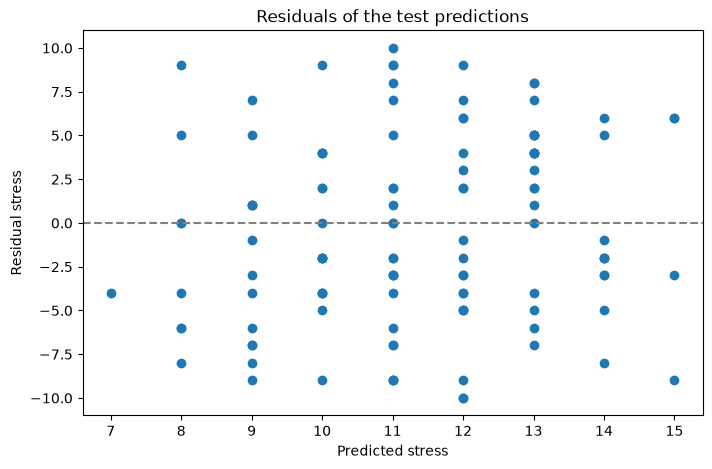

In [62]:
plt.figure(figsize=(8, 5))
plt.scatter(results1['predicted_stress'], results1['residual'])
plt.axhline(0, linestyle='--', color='grey')
plt.xlabel('Predicted stress')
plt.ylabel('Residual stress')
plt.title('Residuals of the test predictions')
plt.show()

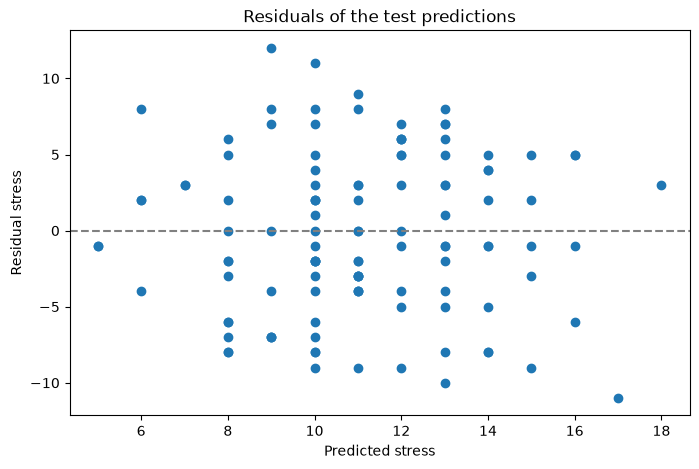

In [63]:
plt.figure(figsize=(8, 5))
plt.scatter(results2['predicted_stress'], results2['residual'])
plt.axhline(0, linestyle='--', color='grey')
plt.xlabel('Predicted stress')
plt.ylabel('Residual stress')
plt.title('Residuals of the test predictions')
plt.show()

In [64]:
train_predictions1 = model_1.predict(X1_train)
train_residuals1 = y_train.values - train_predictions1
train_sse1 = np.sum(train_residuals1 ** 2)

print(f'Training sum of squared errors: {train_sse1:,.0f}')

Training sum of squared errors: 10,034


In [65]:
train_predictions2 = model_2.predict(X2_train)
train_residuals2 = y_train.values - train_predictions2
train_sse2 = np.sum(train_residuals2 ** 2)

print(f'Training sum of squared errors: {train_sse2:,.0f}')

Training sum of squared errors: 8,702


In [66]:
def regression_metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {
        'MAE': mean_absolute_error(y_true, y_hat),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R²': r2_score(y_true, y_hat),
    }

metrics_1f = pd.DataFrame({
    'Training': regression_metrics(y_train, model_1.predict(X1_train)),
    'Test': regression_metrics(y_test, y_pred1),
})
metrics_1f.style.format('{:,.3f}', subset=pd.IndexSlice[['R²'], :]) \
                .format('{:,.0f}', subset=pd.IndexSlice[['MAE', 'MSE', 'RMSE'], :])

,Training,Test
MAE,4,5
MSE,22,28
RMSE,5,5
R²,0.134,0.174


In [67]:
def regression_metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {
        'MAE': mean_absolute_error(y_true, y_hat),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R²': r2_score(y_true, y_hat),
    }

metrics_1f = pd.DataFrame({
    'Training': regression_metrics(y_train, model_2.predict(X2_train)),
    'Test': regression_metrics(y_test, y_pred2),
})
metrics_1f.style.format('{:,.3f}', subset=pd.IndexSlice[['R²'], :]) \
                .format('{:,.0f}', subset=pd.IndexSlice[['MAE', 'MSE', 'RMSE'], :])

,Training,Test
MAE,4,4
MSE,19,28
RMSE,4,5
R²,0.249,0.194


In [68]:
comparison = pd.DataFrame({
    'demographic_lifestyle only (test)': regression_metrics(y_test, y_pred1),
    'big_five (test)': regression_metrics(y_test, y_pred2),
})
comparison.drop(index='MSE').round(3)

,demographic_lifestyle only (test),big_five (test)
MAE,4.609,4.445
RMSE,5.331,5.267
R²,0.174,0.194


In [69]:
print(f"Correlation between extraversion and stress: {df_model['Extraversion'].corr(df_model['DASS_total']):.2f}")

Correlation between extraversion and stress: -0.04


In [70]:
df_linear = df_analysis.copy()
df_logistic = df_analysis.copy()
df_knn = df_analysis.copy()
df_tree = df_analysis.copy()

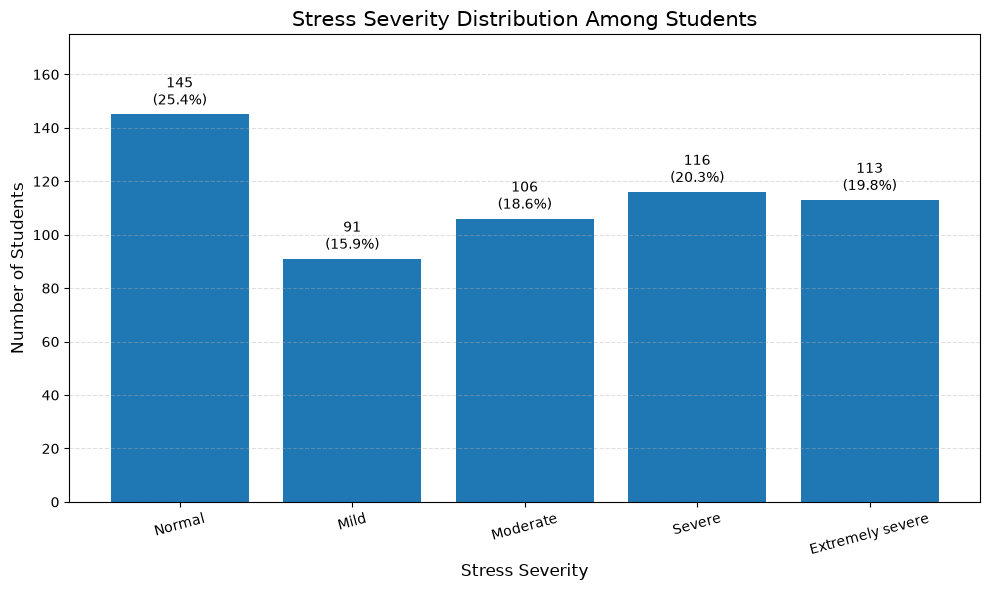

Stress severity distribution:
                  Number of students  Percentage
Stress_category                                 
Normal                           145        25.4
Mild                              91        15.9
Moderate                         106        18.6
Severe                           116        20.3
Extremely severe                 113        19.8


In [71]:
stress_order = [
    "Normal",
    "Mild",
    "Moderate",
    "Severe",
    "Extremely severe"
]

stress_counts = (
    df_analysis["Stress_category"]
    .value_counts()
    .reindex(stress_order, fill_value=0)
)

stress_percentages = (
    stress_counts / stress_counts.sum() * 100
)

plt.figure(figsize=(10, 6))

bars = plt.bar(
    stress_counts.index,
    stress_counts.values
)

for bar, count, percentage in zip(
    bars,
    stress_counts.values,
    stress_percentages.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.title(
    "Stress Severity Distribution Among Students",
    fontsize=15
)

plt.xlabel("Stress Severity", fontsize=12)
plt.ylabel("Number of Students", fontsize=12)

plt.xticks(rotation=15)
plt.ylim(0, stress_counts.max() + 30)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

plt.savefig(
    "stress_severity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Stress severity distribution:")
print(pd.DataFrame({
    "Number of students": stress_counts,
    "Percentage": stress_percentages.round(1)
}))

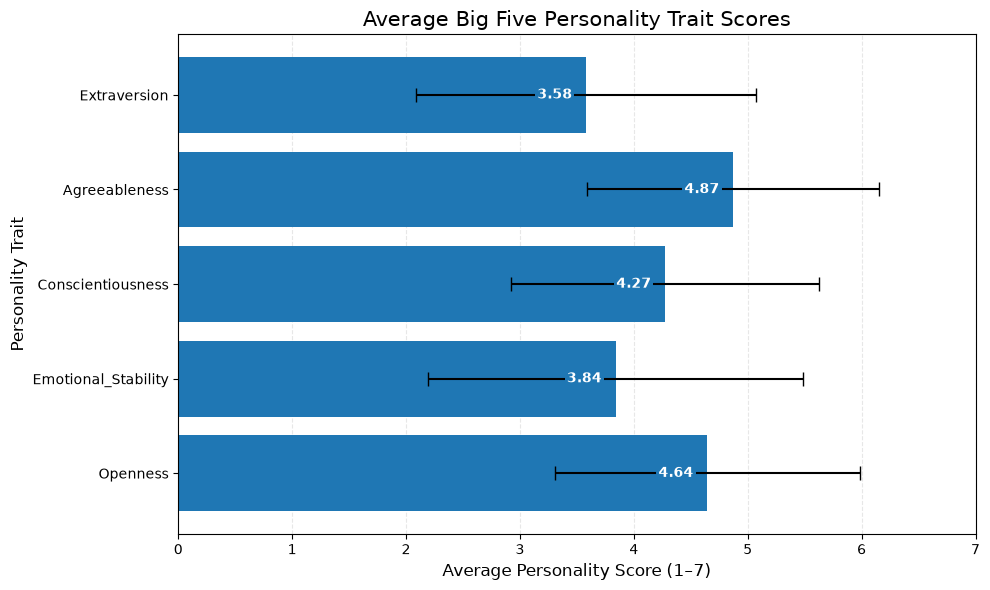

Big Five personality trait summary:
                     mean   std
Extraversion         3.58  1.49
Agreeableness        4.87  1.28
Conscientiousness    4.27  1.35
Emotional_Stability  3.84  1.65
Openness             4.64  1.34


In [74]:
trait_summary = df_analysis[trait_cols].agg(
    ["mean", "std"]
).T

trait_order = [
    "Extraversion",
    "Agreeableness",
    "Conscientiousness",
    "Emotional_Stability",
    "Openness"
]

trait_summary = trait_summary.reindex(trait_order)

means = trait_summary["mean"]
std_devs = trait_summary["std"]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    trait_order,
    means,
    xerr=std_devs,
    capsize=5,
    zorder=2
)

for bar, mean in zip(bars, means):
    ax.text(
        mean - 0.12,
        bar.get_y() + bar.get_height() / 2,
        f"{mean:.2f}",
        va="center",
        ha="right",
        fontsize=10,
        fontweight="bold",
        color="white",
        zorder=4,
        bbox=dict(
            facecolor=bar.get_facecolor(),
            edgecolor="none",
            pad=1.5
        )
    )

ax.set_title(
    "Average Big Five Personality Trait Scores",
    fontsize=15
)

ax.set_xlabel("Average Personality Score (1–7)", fontsize=12)
ax.set_ylabel("Personality Trait", fontsize=12)

ax.set_xlim(0, 7)

ax.invert_yaxis()

ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "big_five_personality_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Big Five personality trait summary:")
print(trait_summary.round(2))